# Milestone M4 — Exploratory Data Analysis (`m4_eda.ipynb`)

**Project:** Predicting Animal Shelter Length of Stay and Outcome Status (Austin Animal Center Pipeline)  
**Team:** Osman Kalkan (`230717048`), Irmak Köse (`230717027`), Ferdi Derebaşı (`230717056`)  
**Database:** `data/austin_animals.db` opened strictly read-only (`file:...?mode=ro`, `uri=True`)  

### Exploration Habits Enforced
1. **Name the question before the summary:** Every section begins with the exact question it answers and reports `n` for every aggregate.
2. **Know the clock and the denominator:** Every time-based query explicitly converts stored UTC timestamps to Austin local time (`America/Chicago`), states its flag filter, and applies explicit coverage rules.
3. **Look before you summarise; doubt before you conclude:** Distributions and relationships are plotted before summary coefficients are interpreted; group comparisons report cluster-bootstrapped 95% confidence intervals, subgroup composition checks (Simpson's paradox), and the total count of candidate looks (`LOOK_COUNT = 12`).

In [1]:
# =====================================================================
# CELL 1: ALL EXPLORATION PARAMETERS, THRESHOLDS, FLAG FILTERS & SEEDS
# =====================================================================
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

from src.explore import (
    COMPANION_SPECIES,
    HIST_BIN_WIDTH_DAYS,
    HIST_MAX_DAYS,
    LOCAL_TZ_NAME,
    LOOK_COUNT,
    MAIN_SPECIES,
    MIN_COMPLETION_RATE,
    MIN_DAYS_PER_MONTH,
    MIN_DOB_COVERAGE,
    MIN_GROUP_OUTCOMES,
    NEONATE_CUTOFF_DAYS,
    PRIMARY_FLAG_FILTER,
    RANDOM_SEED,
    BOOTSTRAP_ITERATIONS,
    STRAY_HOLD_DAYS,
    STRICT_FLAG_FILTER,
    SURGICAL_AGE_DAYS,
    TARGET_STAY_DAYS,
    VALID_SEQUENCE_FLAG,
    compare_histogram_bin_widths,
    compute_age_los_relationship,
    compute_flag_filter_sensitivity,
    compute_hourly_and_weekday_profiles,
    compute_monthly_coverage_and_rule,
    compute_raw_vs_cleaned_table,
    compute_simpsons_paradox_and_intervals,
    compute_species_summary_rankings,
    connect_ro,
    fetch_time_indexed_stays,
    hash_all_tables,
    load_sql_query,
    plot_fig1_raw_vs_cleaned_and_rankings,
    plot_fig2_shape_histogram_and_ecdf,
    plot_fig3_coverage_and_flag_sensitivity,
    plot_fig4_time_clock_and_scales,
    plot_fig5_age_vs_los_relationship,
    plot_fig6_headline_simpsons_paradox,
    verify_readonly_enforcement,
)

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 60)
pd.set_option("display.width", 140)

DB_PATH = ROOT_DIR / "data" / "austin_animals.db"
FIGURES_DIR = ROOT_DIR / "figures"

con = connect_ro(DB_PATH)
ro_verified = verify_readonly_enforcement(con)
hashes_before = hash_all_tables(con)
print(f"Connected read-only (`mode=ro`, `uri=True`) to: {DB_PATH}")
print(f"Read-only write-protection verified: {ro_verified} | Tables hashed before run: {len(hashes_before)}")

Connected read-only (`mode=ro`, `uri=True`) to: C:\Users\huawei\Downloads\datascience\austin-animal-outcomes\data\austin_animals.db
Read-only write-protection verified: True | Tables hashed before run: 10


## 2.1 Raw Versus Cleaned: The Key Number

**Question:** *How do the headline length-of-stay (in days) and live adoption share (%) across completed shelter stays change when computed on the M2 raw tables (`outcomes` + `animals`) versus the M3 cleaned layer (`stays_clean_view` with our reported flag filter `days_in_shelter_flag IN ('ok', 'unusual_high_stay') AND stay_sequence_flag = 'ok'`)?*

In [2]:
sql_2_1 = load_sql_query("m4_raw_vs_cleaned_key_metrics.sql")
print("--- Saved SQL Query (sql/queries/m4_raw_vs_cleaned_key_metrics.sql) ---")
print(sql_2_1)

raw_vs_clean_sql_df = pd.read_sql_query(sql_2_1, con)
print("SQL Aggregation Result (M2 Raw vs M3 Cleaned):")
display(raw_vs_clean_sql_df)

rvc_detailed_df = compute_raw_vs_cleaned_table(con)
print("Detailed Quantile & Subtype Comparison (M2 Raw vs M3 Cleaned):")
display(rvc_detailed_df)

--- Saved SQL Query (sql/queries/m4_raw_vs_cleaned_key_metrics.sql) ---
-- =====================================================================
-- M4 Section 2.1 & 2.2: Raw (M2) vs Cleaned (M3) Key Project Numbers
-- Question: How do length of stay (days) and live adoption rate (%)
--           compare between the raw M2 tables and the M3 cleaned layer?
-- Result grain: One row per (layer, animal_group).
-- Flag filter on M3 layer:
--   days_in_shelter_flag IN ('ok', 'unusual_high_stay')
--   AND stay_sequence_flag = 'ok'
-- =====================================================================

WITH raw_stays AS (
    SELECT
        '1_M2_Raw' AS layer,
        CASE
            WHEN a.animal_type IN ('Cat', 'Dog', 'Kitten', 'Puppy', 'Mammal') THEN a.animal_type
            ELSE 'Other_Raw'
        END AS group_label,
        CAST(o.days_in_shelter AS REAL) AS stay_days_int,
        (julianday(o.outcome_at) - julianday(o.intake_at)) AS stay_days_exact,
        CASE WHEN o.outcome_statu

,layer,group_label,n_completed_stays,mean_days_integer,mean_los_days,adopted_exact_pct,adopted_canonical_pct
0,1_M2_Raw,ALL_STAYS,17670,23.04,23.09,45.27,49.69
1,1_M2_Raw,Cat,8739,20.79,20.85,52.04,57.41
2,1_M2_Raw,Dog,6133,29.77,29.84,47.76,52.67
3,1_M2_Raw,Kitten,1529,8.08,8.11,21.06,21.26
4,1_M2_Raw,Mammal,687,31.92,31.93,0.00,0.00
5,1_M2_Raw,Puppy,297,8.21,8.24,32.66,32.66
6,1_M2_Raw,Other_Raw,285,21.29,21.27,36.49,38.95
7,2_M3_Cleaned,ALL_STAYS,17608,23.05,23.10,49.82,49.82
8,2_M3_Cleaned,Cat,10242,18.92,18.98,52.12,52.12
9,2_M3_Cleaned,Dog,6407,28.76,28.82,51.87,51.87


Detailed Quantile & Subtype Comparison (M2 Raw vs M3 Cleaned):


,cohort,layer,n,median_los_d,iqr_los_d,mean_los_d,p90_los_d,p95_los_d,adopted_exact_pct,adopted_all_subtypes_pct
0,M2 Raw — All Outcomes (unfiltered),M2 Raw,17670,8.06,23.98,23.09,60.36,90.05,45.27,49.69
1,M3 Cleaned — All Valid Completed Stays,M3 Cleaned,17608,8.07,24.03,23.10,60.45,90.05,49.82,49.82
2,M2 Raw — 'Cat' (excludes raw 'Kitten'),M2 Raw,8739,8.50,24.28,20.85,55.60,72.23,52.04,57.41
3,M2 Raw — 'Kitten' (separate raw type),M2 Raw,1529,3.95,6.99,8.11,20.35,39.37,21.06,21.26
4,M3 Cleaned — Canonical 'Cat' (Adult + Juvenile),M3 Cleaned,10242,7.27,21.30,18.98,52.21,69.79,52.12,52.12
5,M2 Raw — 'Dog' (excludes raw 'Puppy'),M2 Raw,6133,9.99,29.00,29.84,80.07,129.42,47.76,52.67
6,M2 Raw — 'Puppy' (separate raw type),M2 Raw,297,5.04,5.64,8.24,17.21,24.58,32.66,32.66
7,M3 Cleaned — Canonical 'Dog' (Adult + Juvenile),M3 Cleaned,6407,9.17,27.18,28.82,77.81,125.10,51.87,51.87


## 2.2 The Question, and the Summary That Answers It

**Project Question (One Sentence):** *How do an animal's canonical species, life stage (`juvenile` vs. `adult`), intake channel, and reproductive status relate to how long it stays at the Austin Animal Center (`length_of_stay_days`) and whether its stay ends in live adoption (`outcome_status = 'Adopted'`)?*

**Why Median (with IQR) + 95th Percentile + Adoption Rate (%) Answers It:**  
Because shelter length of stay is bounded at zero and strongly right-skewed (`max = 484` days), the arithmetic mean is pulled upward by the ~4% tail of long-term medical/behavioral/court-hold stays. The **median** (`p50`) answers *"How long does a typical arrival wait before exit?"*, while the **90th/95th percentile (`p90`/`p95`)** answers *"Which group places the heaviest long-term burden on shelter kennel capacity?"* Below we compute all summaries with `n` for every group and test whether group rankings reverse across summaries.

Species Summary Table with Explicit n, Coverage Rule Check (n >= 30), and Ranks by Median vs Mean vs p95:


,animal_type,n,passes_coverage_rule,median_d,iqr_d,mean_d,sd_d,p90_d,p95_d,share_gt_14d_pct,share_gt_30d_pct,adoption_rate_pct,rank_by_median,rank_by_mean,rank_by_p95
0,Cat,10242,True,7.27,21.30,18.98,27.98,52.21,69.79,35.1,21.4,52.1,3.0,5.0,6.0
1,Dog,6407,True,9.17,27.18,28.82,49.54,77.81,125.10,40.9,25.9,51.9,2.0,2.0,2.0
2,Wildlife,692,True,4.02,33.70,31.55,56.44,96.11,163.96,40.5,26.7,0.0,6.0,1.0,1.0
3,Small Mammal,141,True,14.06,35.94,24.80,26.22,54.06,74.24,50.4,31.9,52.5,1.0,4.0,5.0
4,Bird,77,True,5.80,21.48,17.07,26.64,46.58,82.89,35.1,16.9,23.4,5.0,6.0,4.0
5,Reptile,39,True,6.99,18.80,25.94,70.47,37.31,91.76,28.2,12.8,33.3,4.0,3.0,3.0
6,Other,6,False,5.45,2.58,7.88,5.40,13.32,15.97,16.7,0.0,83.3,NaN,NaN,NaN
7,Livestock,4,False,5.17,5.10,8.46,7.23,15.29,17.26,25.0,0.0,25.0,NaN,NaN,NaN


Saved Figure 1 -> figures\fig1_raw_vs_cleaned_impact.png


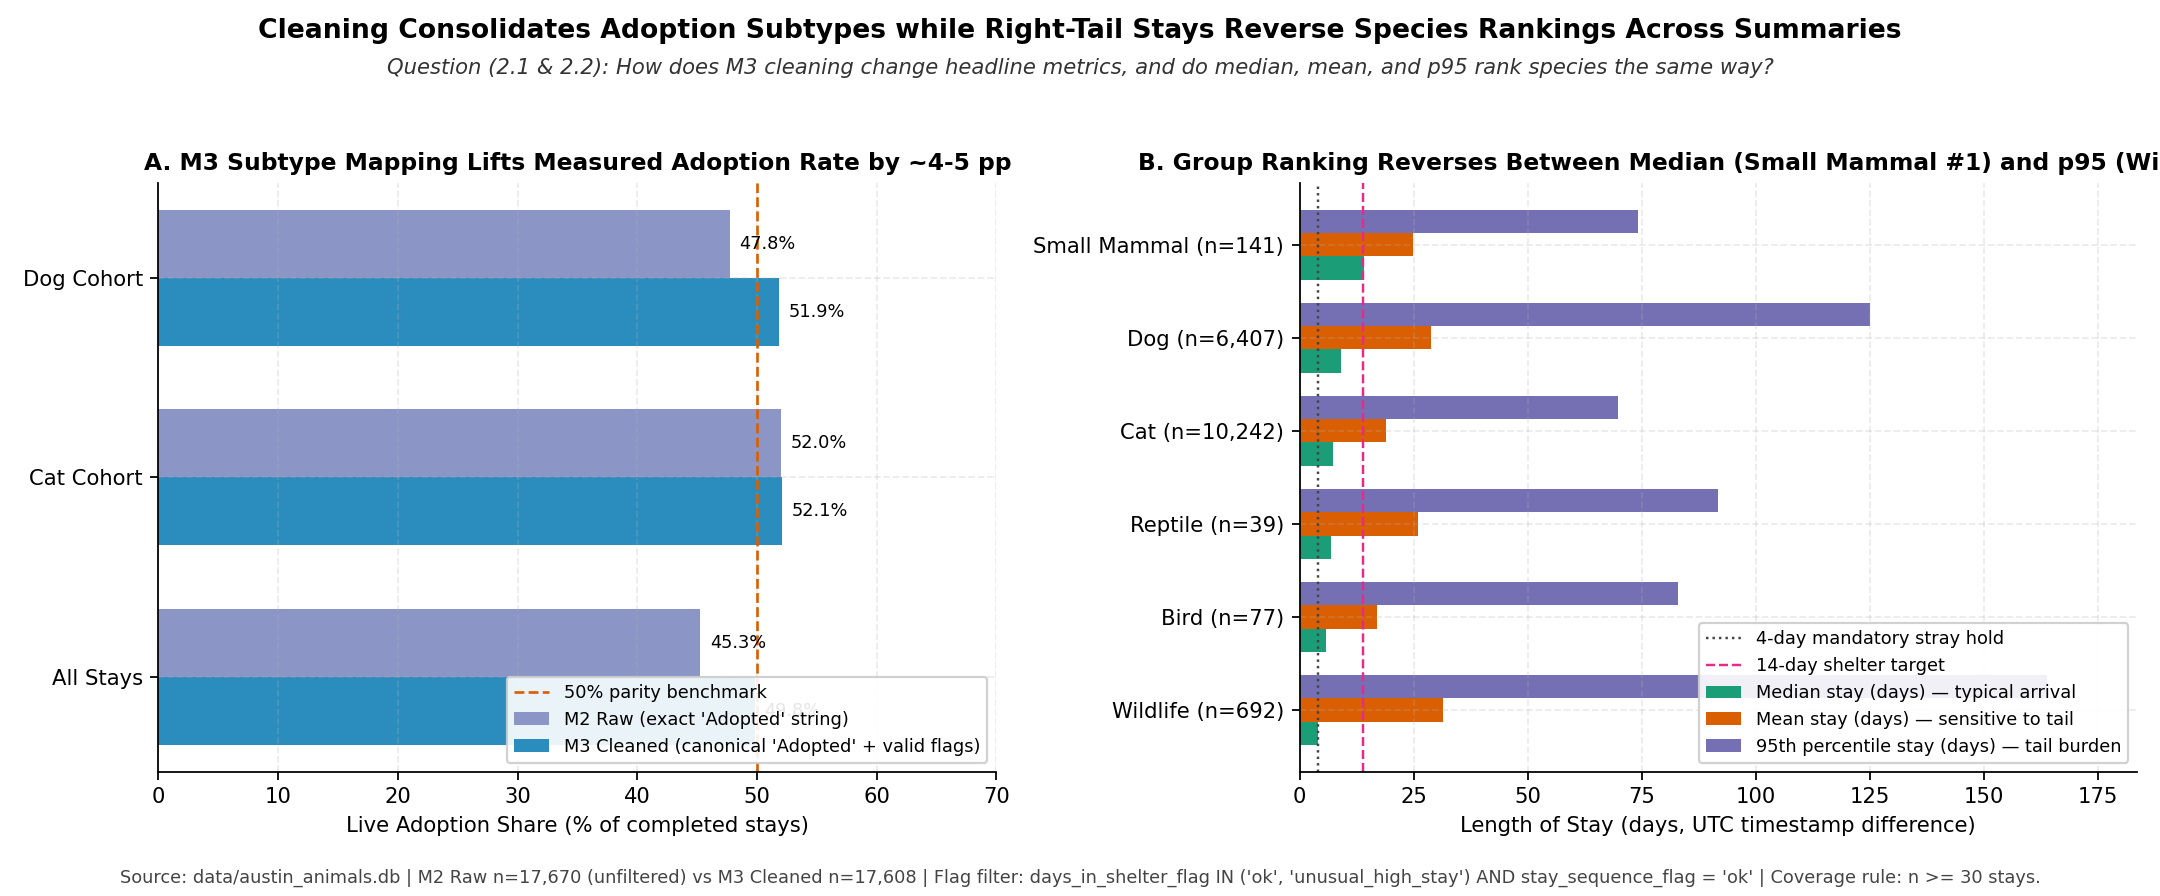

In [3]:
rankings_df = compute_species_summary_rankings(con)
print("Species Summary Table with Explicit n, Coverage Rule Check (n >= 30), and Ranks by Median vs Mean vs p95:")
display(rankings_df)

fig1_path = plot_fig1_raw_vs_cleaned_and_rankings(con, FIGURES_DIR)
print(f"Saved Figure 1 -> {fig1_path.relative_to(ROOT_DIR)}")
display(Image(filename=str(fig1_path)))

## 2.3 Shape of the Key Variable (`length_of_stay_days`)

**Question:** *What is the distributional shape of `length_of_stay_days` overall and across our main species and life-stage groups when inspected via a justified natural-unit histogram and a log-scale ECDF?*

Justification of Chosen 2-Day Natural Bin Width (tested against 1-day and 7-day bins):


,bin_width_days,n_bins_0_to_90d,primary_mode_bin,primary_mode_count,secondary_mode_bin,empty_bin_pct,assessment
0,1.0,90,"[0d, 1d)",2323,"[3d, 4d)",0.0,1-day (daily bins; noisy sawtooth from weekend...
1,2.0,45,"[0d, 2d)",3127,"[4d, 6d)",0.0,2-day (chosen: resolves day 0-2 intake triage ...
2,7.0,13,"[0d, 7d)",8020,"[7d, 14d)",0.0,7-day (weekly bins; over-smooths and hides the...


Saved Figure 2 -> figures\fig2_los_shape_hist_ecdf.png


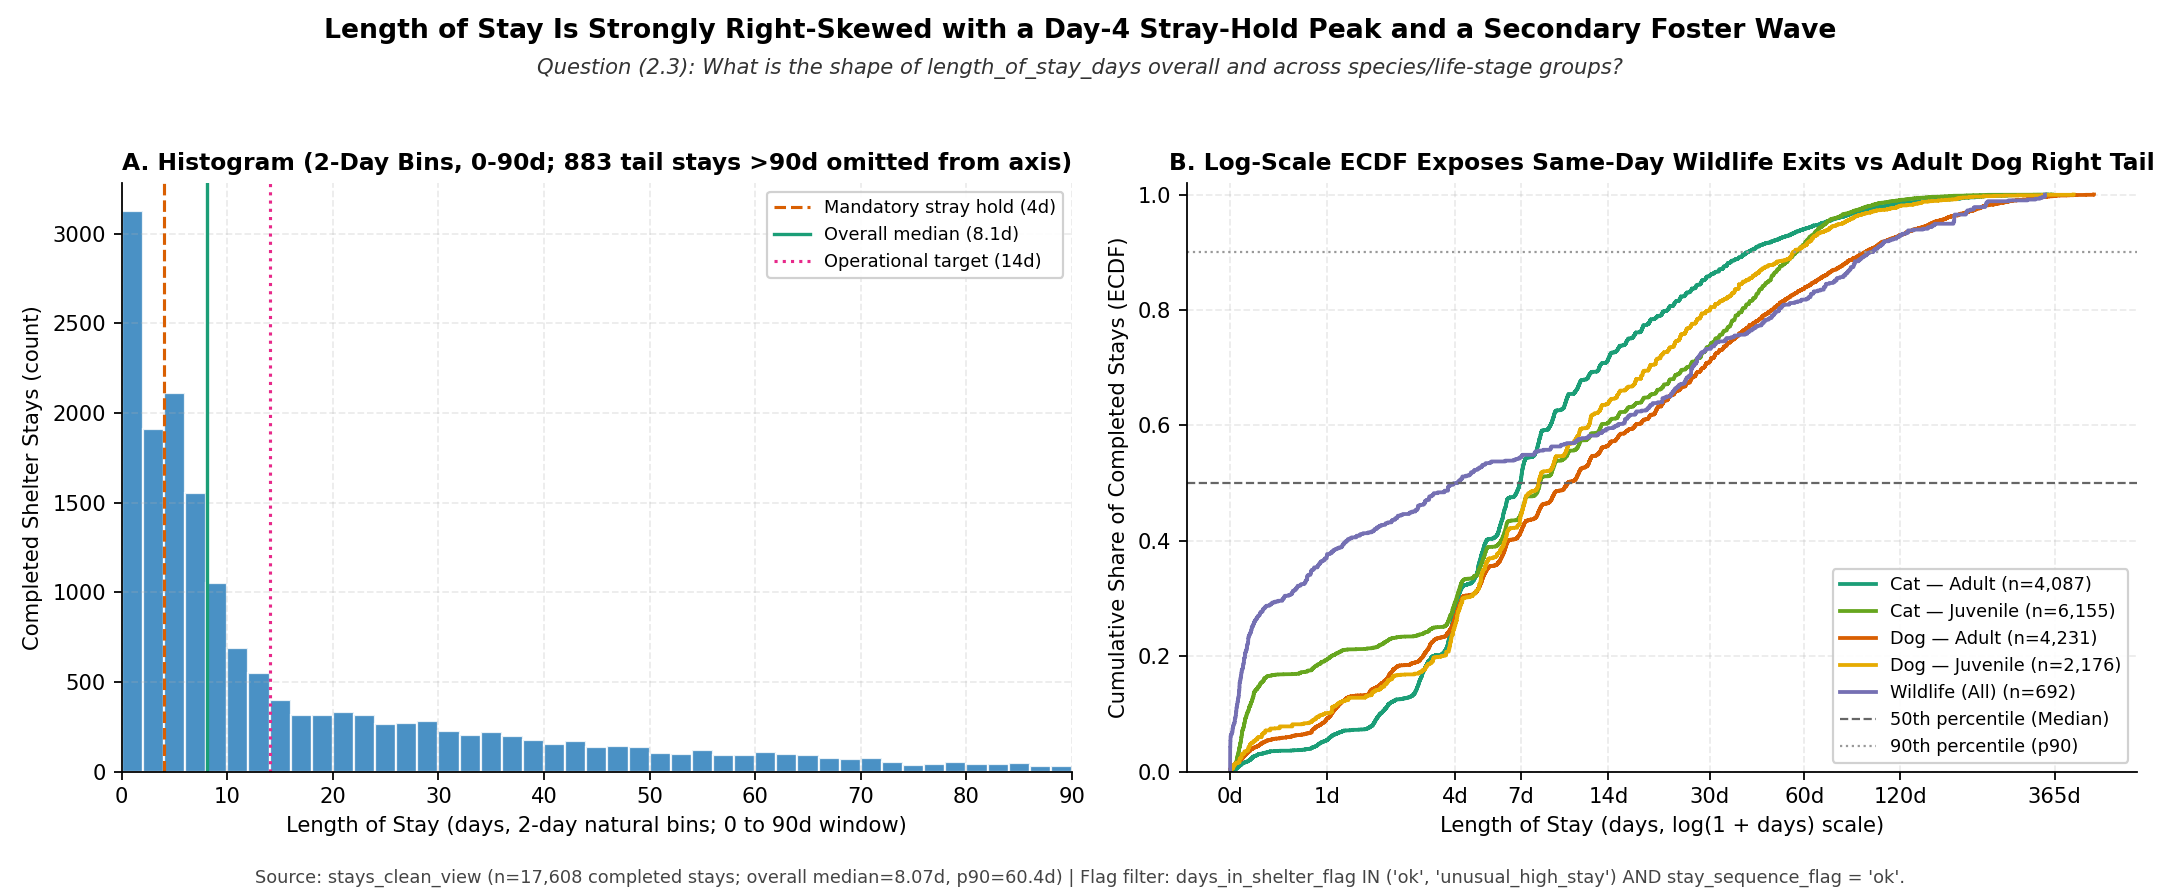

In [4]:
bin_check_df = compare_histogram_bin_widths(con)
print("Justification of Chosen 2-Day Natural Bin Width (tested against 1-day and 7-day bins):")
display(bin_check_df)

fig2_path = plot_fig2_shape_histogram_and_ecdf(con, FIGURES_DIR)
print(f"Saved Figure 2 -> {fig2_path.relative_to(ROOT_DIR)}")
display(Image(filename=str(fig2_path)))

## 2.4 Coverage, Denominators, and the Flag Filter

**Question:** *Which species groups and calendar months have thin coverage or right-censored denominators, and how do our explicit coverage rules (`n >= 30` stays, `>= 80%` DOB coverage, `>= 20` active days/month, `>= 85%` cohort completion) and flag filter choices (`ok + unusual_high_stay` vs. `ok only`) alter the reported numbers?*

Entity Coverage Table by Canonical Species x Life Stage (with DOB, Sex, ZIP, and Health Coverage %):


,animal_type,life_stage,n_intakes,n_completed_stays,n_open_stays,completion_rate_pct,dob_coverage_pct,sex_coverage_pct,zip_coverage_pct,health_logged_pct,n_unusual_high_stay
0,Cat,juvenile,6401,6155,245,96.2,94.8,86.8,91.7,11.8,162
1,Dog,adult,4752,4231,520,89.0,95.9,96.8,81.6,19.6,323
2,Cat,adult,4257,4087,170,96.0,93.3,84.1,86.8,16.7,121
3,Dog,juvenile,2229,2176,53,97.6,96.5,90.4,86.0,15.5,52
4,Wildlife,unknown,665,521,144,78.3,0.0,1.8,62.4,32.6,26
5,Wildlife,adult,186,152,34,81.7,100.0,3.2,91.4,44.1,15
6,Small Mammal,adult,85,80,5,94.1,100.0,80.0,78.8,15.3,0
7,Bird,unknown,56,52,4,92.9,0.0,16.1,87.5,21.4,4
8,Small Mammal,unknown,47,46,1,97.9,0.0,80.9,93.6,25.5,0
9,Reptile,unknown,28,25,3,89.3,0.0,14.3,64.3,25.0,1


Monthly Coverage Table in America/Chicago Local Time (Showing Results With and Without Coverage Rule):


,intake_local_month,calendar_days,active_local_days,first_local_date,last_local_date,n_intakes,n_completed,completion_pct,juvenile_intake_pct,median_los_d,mean_los_d,adoption_rate_pct,passes_coverage_rule,coverage_status
0,2025-05,31,28,2025-05-04,2025-05-31,1237,1233,99.7,55.8,10.83,31.82,53.9,True,INCLUDED (complete & uncensored)
1,2025-06,30,30,2025-06-01,2025-06-30,1352,1344,99.4,59.8,19.07,33.25,56.7,True,INCLUDED (complete & uncensored)
2,2025-07,31,31,2025-07-01,2025-07-31,1131,1117,98.8,50.0,11.80,33.61,57.8,True,INCLUDED (complete & uncensored)
3,2025-08,31,31,2025-08-01,2025-08-31,1017,1012,99.5,47.0,14.07,35.22,58.8,True,INCLUDED (complete & uncensored)
4,2025-09,30,30,2025-09-01,2025-09-30,1002,992,99.0,49.4,13.21,32.01,55.9,True,INCLUDED (complete & uncensored)
5,2025-10,31,31,2025-10-01,2025-10-31,1069,1059,99.1,44.2,10.86,30.20,50.3,True,INCLUDED (complete & uncensored)
6,2025-11,30,30,2025-11-01,2025-11-30,730,712,97.5,37.5,11.12,26.71,52.7,True,INCLUDED (complete & uncensored)
7,2025-12,31,31,2025-12-01,2025-12-31,649,643,99.1,37.3,7.96,21.99,45.9,True,INCLUDED (complete & uncensored)
8,2026-01,31,31,2026-01-01,2026-01-31,732,714,97.5,29.2,7.12,22.95,51.0,True,INCLUDED (complete & uncensored)
9,2026-02,28,28,2026-02-01,2026-02-28,812,787,96.9,29.7,6.92,24.20,51.5,True,INCLUDED (complete & uncensored)


Flag Filter Sensitivity Table — Filter A ('ok' + 'unusual_high_stay') vs Filter B ('ok' only):


,animal_type,n_filter_A_all_valid,n_filter_B_ok_only,n_unusual_removed,median_A_d,median_B_d,mean_A_d,mean_B_d,p95_A_d,p95_B_d,adopt_A_pct,adopt_B_pct
0,Cat,10242,9959,283,7.27,7.14,18.98,15.76,69.79,59.99,52.1,51.2
1,Dog,6407,6032,375,9.17,8.14,28.82,18.75,125.10,73.50,51.9,49.9
2,Wildlife,692,650,42,4.02,3.06,31.55,19.91,163.96,91.75,0.0,0.0
3,Small Mammal,141,141,0,14.06,14.06,24.80,24.80,74.24,74.24,52.5,52.5
4,Bird,77,73,4,5.80,4.99,17.07,12.08,82.89,46.58,23.4,21.9
5,Reptile,39,36,3,6.99,6.56,25.94,10.01,91.76,28.22,33.3,33.3


Saved Figure 3 -> figures\fig3_coverage_and_flag_sensitivity.png


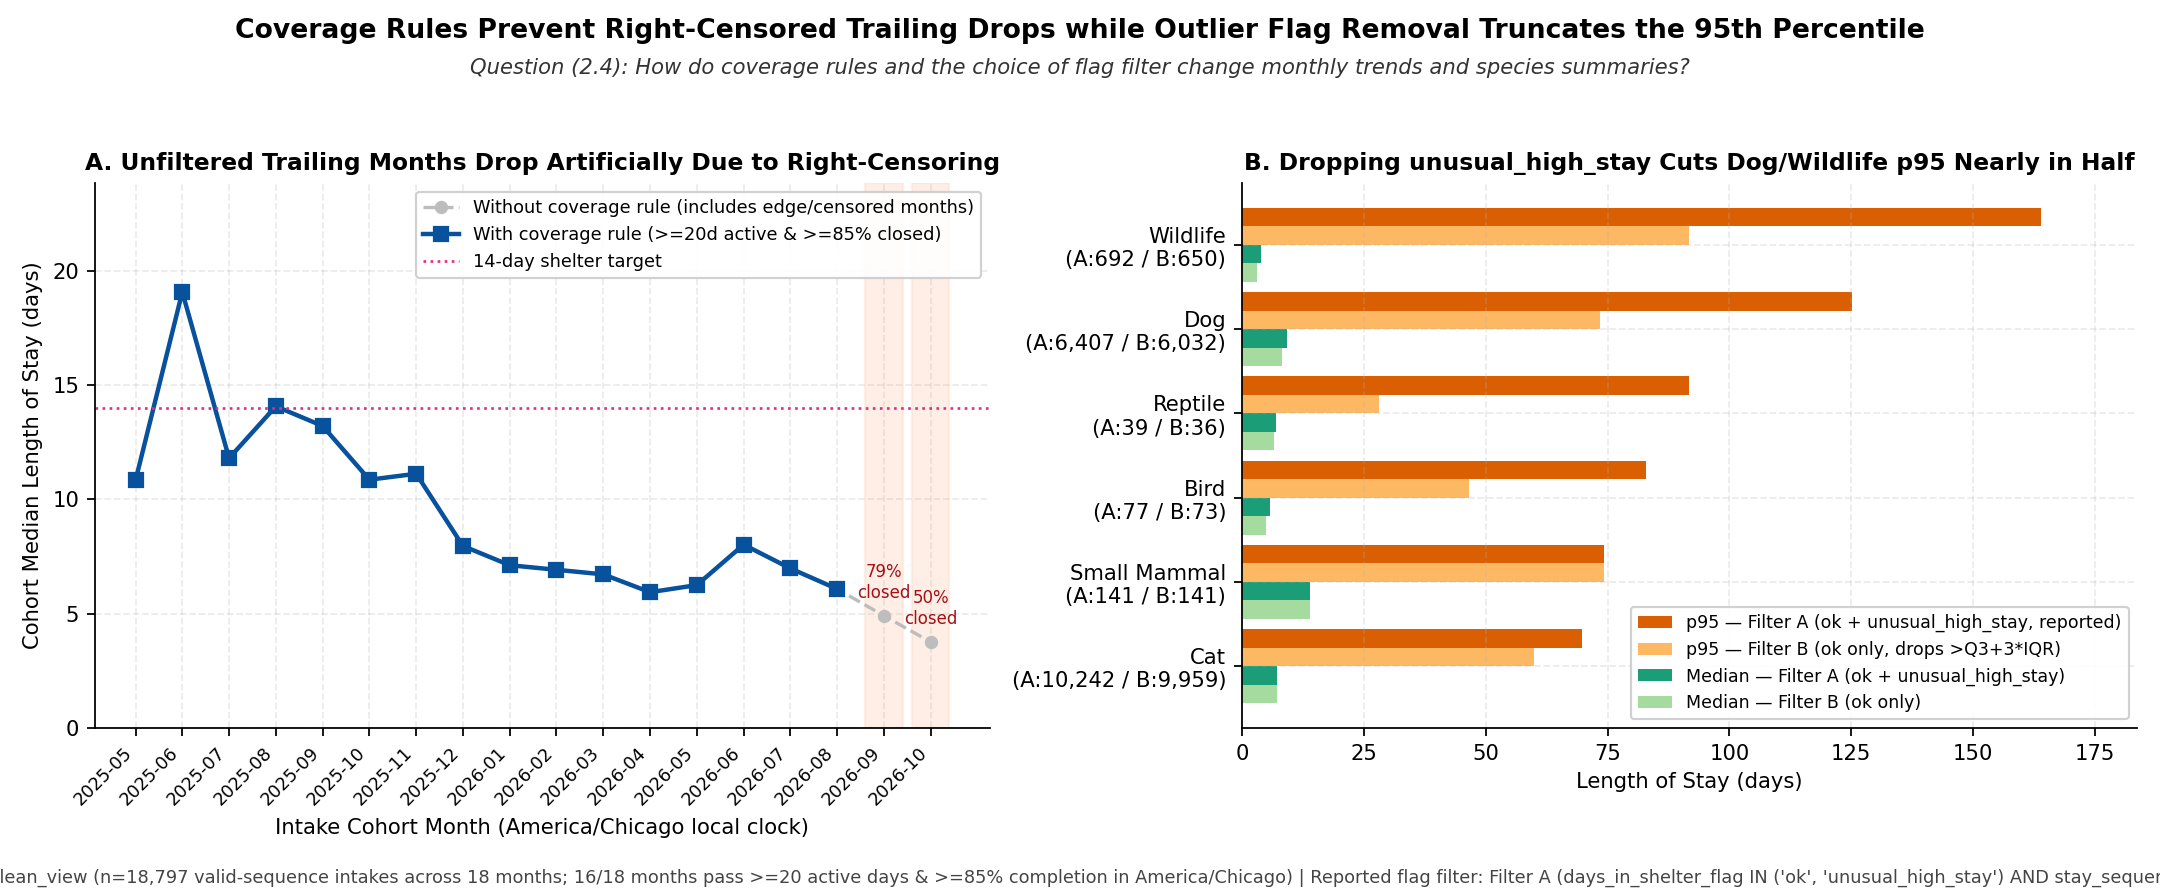

In [5]:
sql_2_4 = load_sql_query("m4_coverage_by_species_and_month.sql")
cov_species_df = pd.read_sql_query(sql_2_4, con)
print("Entity Coverage Table by Canonical Species x Life Stage (with DOB, Sex, ZIP, and Health Coverage %):")
display(cov_species_df)

df_time = fetch_time_indexed_stays(con)
monthly_cov_df = compute_monthly_coverage_and_rule(df_time)
print("Monthly Coverage Table in America/Chicago Local Time (Showing Results With and Without Coverage Rule):")
display(monthly_cov_df)

flag_sens_df = compute_flag_filter_sensitivity(con)
print("Flag Filter Sensitivity Table — Filter A ('ok' + 'unusual_high_stay') vs Filter B ('ok' only):")
display(flag_sens_df)

fig3_path = plot_fig3_coverage_and_flag_sensitivity(con, FIGURES_DIR)
print(f"Saved Figure 3 -> {fig3_path.relative_to(ROOT_DIR)}")
display(Image(filename=str(fig3_path)))

## 2.5 Time: Clock Choice, Edges, Two Time Scales, and Calendar Effects

**Question:** *How do shelter intake volumes and stay durations vary across hours of the day, days of the week, seasonal months, and major calendar holidays once timestamps are explicitly converted from UTC to Austin local wall-clock time (`America/Chicago`)?*

Day-of-Week Intake Profile in America/Chicago Local Time:


,day_of_week,n_calendar_dates,total_intakes,mean_intakes_per_day,stray_aco_per_day,owner_community_per_day
0,Monday,77,3171,41.18,24.14,15.69
1,Tuesday,77,3367,43.73,25.19,16.87
2,Wednesday,76,3074,40.45,24.80,14.46
3,Thursday,76,3101,40.80,24.53,14.58
4,Friday,76,3079,40.51,21.96,17.12
5,Saturday,76,1737,22.86,15.53,5.64
6,Sunday,77,1268,16.47,11.68,3.49


Calendar & Holiday Check (Independence Day July 4th Stray Surge vs Holiday Front-Desk Closures):


,local_date,calendar_event,n_intakes,stray_aco_intakes,owner_surrenders,vs_median_day_pct,operational_interpretation
0,2025-07-04,Independence Day (July 4th),10,10,0,-70.6,Holiday closure / fireworks evening
1,2025-07-05,Post-July 4th Stray Surge (Day +1),26,18,0,-23.5,Fireworks runaway impound surge
2,2025-07-07,Post-July 4th Weekday Reopening,42,28,3,23.5,Post-holiday backlog & stray surge
3,2025-11-27,Thanksgiving Day 2025,3,2,0,-91.2,Shelter front-desk holiday closure
4,2025-12-25,Christmas Day 2025,7,7,0,-79.4,Shelter front-desk holiday closure
5,2026-01-01,New Year's Day 2026,4,3,0,-88.2,Shelter front-desk holiday closure
6,2026-07-04,Independence Day 2026,11,11,0,-67.6,Holiday closure / fireworks evening
7,2026-07-07,Post-July 4th Surge 2026 (Tue),64,42,2,88.2,Post-fireworks stray/ACO impound peak


Saved Figure 4 -> figures\fig4_time_clock_and_scales.png


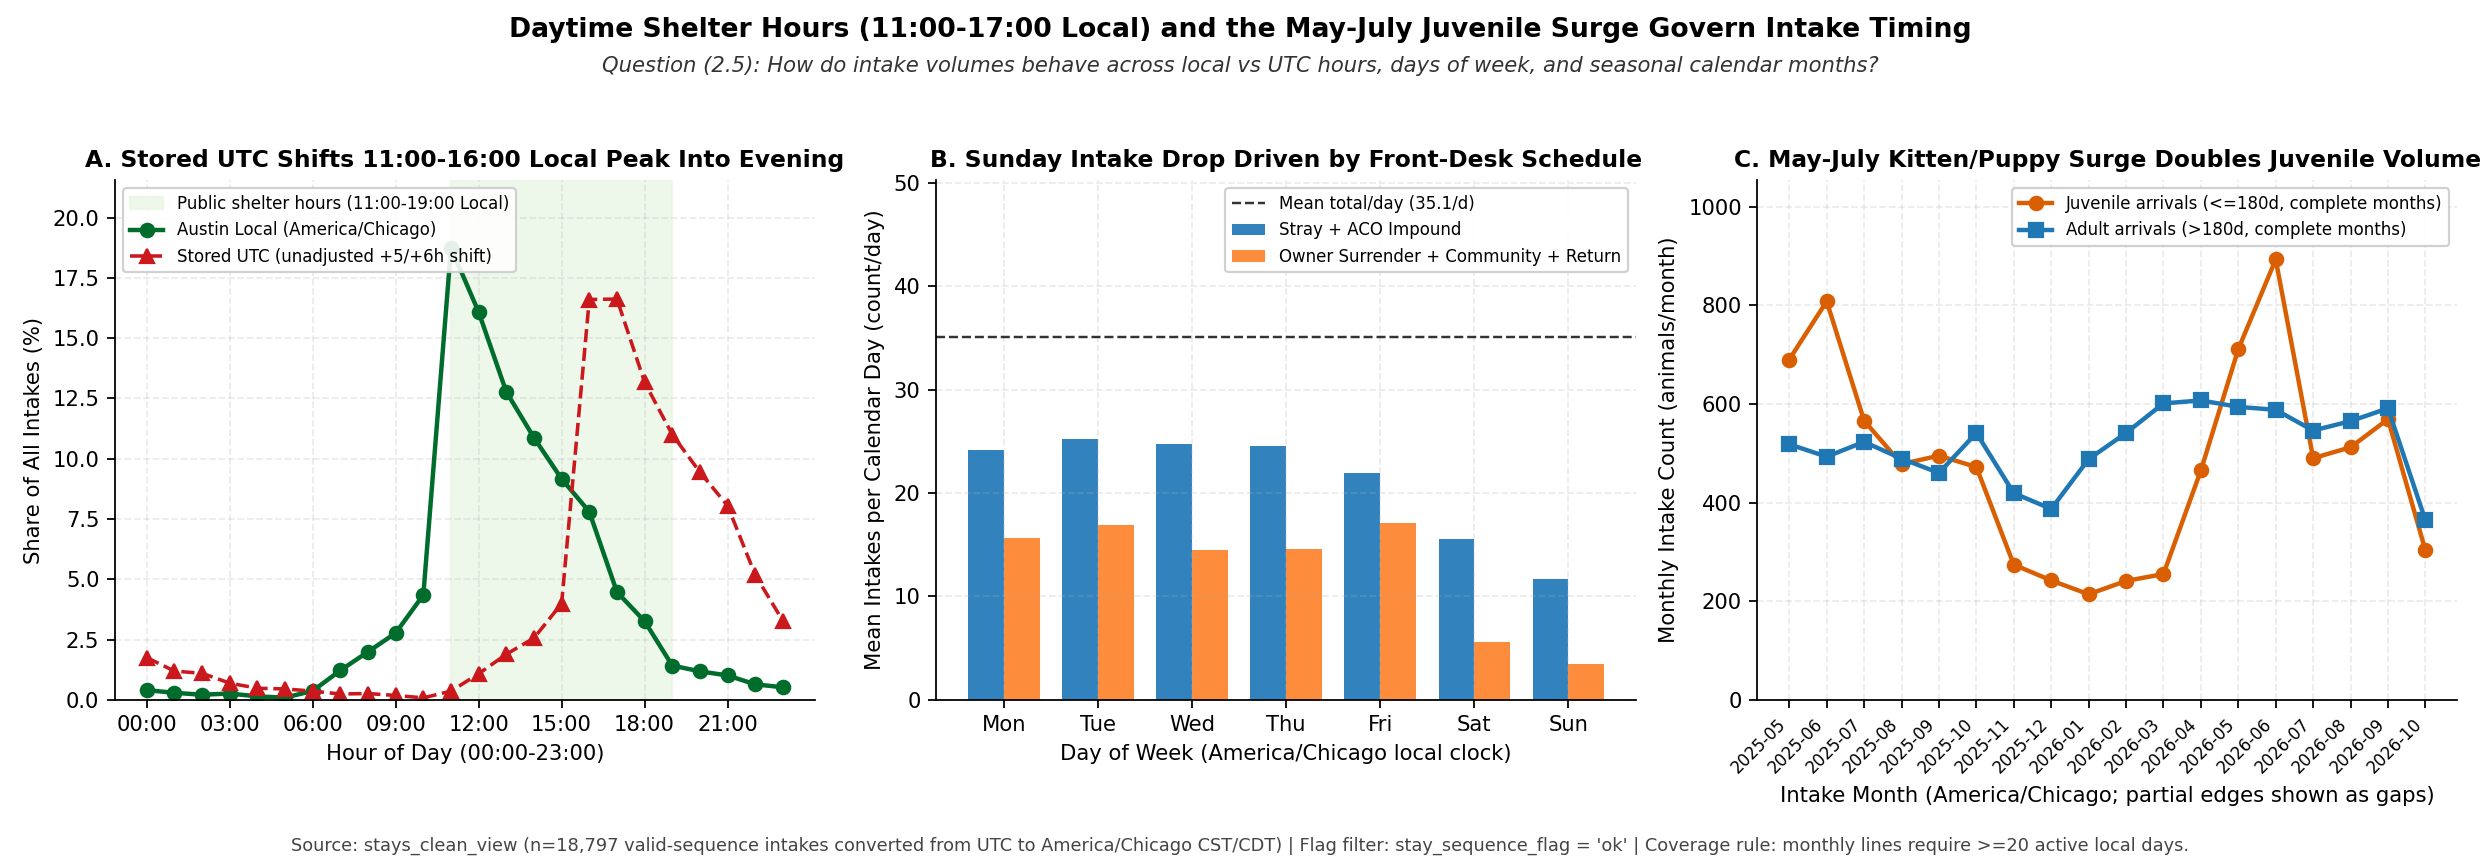

In [6]:
sql_2_5 = load_sql_query("m4_time_patterns_and_edges.sql")
utc_edges_df = pd.read_sql_query(sql_2_5, con)
hourly_df, dow_df, cal_df = compute_hourly_and_weekday_profiles(df_time)

print("Day-of-Week Intake Profile in America/Chicago Local Time:")
display(dow_df)

print("Calendar & Holiday Check (Independence Day July 4th Stray Surge vs Holiday Front-Desk Closures):")
display(cal_df)

fig4_path = plot_fig4_time_clock_and_scales(con, FIGURES_DIR)
print(f"Saved Figure 4 -> {fig4_path.relative_to(ROOT_DIR)}")
display(Image(filename=str(fig4_path)))

## 2.6 Relationships: Age at Intake vs. Length of Stay Until Adoption

**Question:** *How does an animal's age at intake (`age_at_intake_days`) relate to its length of stay until adoption (`length_of_stay_days`), why do pooled Pearson's $r$ and Spearman's $\rho$ have opposite signs, and what happens when we remove `< 42`-day neonates or `unusual_high_stay` outliers or stratify by species and season?*

Age-Binned Median & IQR Length of Stay (Days) for Adopted Cats vs Adopted Dogs:


,animal_type,age_bin,mid_age_months,n,q25_los_d,median_los_d,q75_los_d,mean_los_d
0,Cat,0-4w (<1m),0.50,359,43.47,54.77,64.88,56.95
1,Cat,4-6w (1-1.5m),1.25,816,27.19,38.18,55.23,42.94
2,Cat,6-8w (1.5-2m),1.75,614,7.91,16.89,35.78,24.90
3,Cat,2-3m,2.50,895,7.03,11.19,28.23,21.38
4,Cat,3-6m,4.50,842,7.01,11.30,31.20,23.51
5,Cat,6-12m,9.00,605,7.10,11.92,28.35,24.33
6,Cat,1-2y,18.00,347,6.71,13.10,27.11,23.29
7,Cat,2-5y,36.00,579,7.05,14.12,34.10,28.75
8,Cat,5y+,72.00,240,6.20,13.93,34.41,29.46
9,Dog,0-4w (<1m),0.50,54,55.18,62.71,72.03,65.71


Pearson r vs Spearman rho Sensitivity & Driver Removal Checks:


,subset_check,n,pearson_r,spearman_rho,median_age_d,median_los_d
0,1. All Adopted Cat + Dog (ok + unusual_high_stay),8606,0.0744,-0.1044,130.0,20.46
1,2. Remove unusual_high_stay tail (ok only),8062,-0.0239,-0.1767,122.0,18.16
2,"3. Juvenile Adopted Cats (age <= 180d, all valid)",3526,-0.2848,-0.4650,56.0,24.16
3,4. Juvenile Adopted Cats — remove <42d neonates,2709,-0.0813,-0.2304,63.0,15.15
4,5. Juvenile Adopted Cats — Peak Season (May-Aug),2307,-0.2962,-0.4620,56.0,28.10
5,6. Juvenile Adopted Cats — Off-Peak (Sep-Apr),1219,-0.2547,-0.4326,63.0,19.12
6,"7. Juvenile Adopted Dogs (age <= 180d, all valid)",1208,0.0158,-0.0810,70.0,15.15
7,8. Adult Adopted Cats (age > 180d),1771,0.0524,0.0425,730.0,13.09
8,9. Adult Adopted Dogs (age > 180d),2101,-0.0141,0.0111,731.0,27.15


Saved Figure 5 -> figures\fig5_age_vs_los_relationship.png


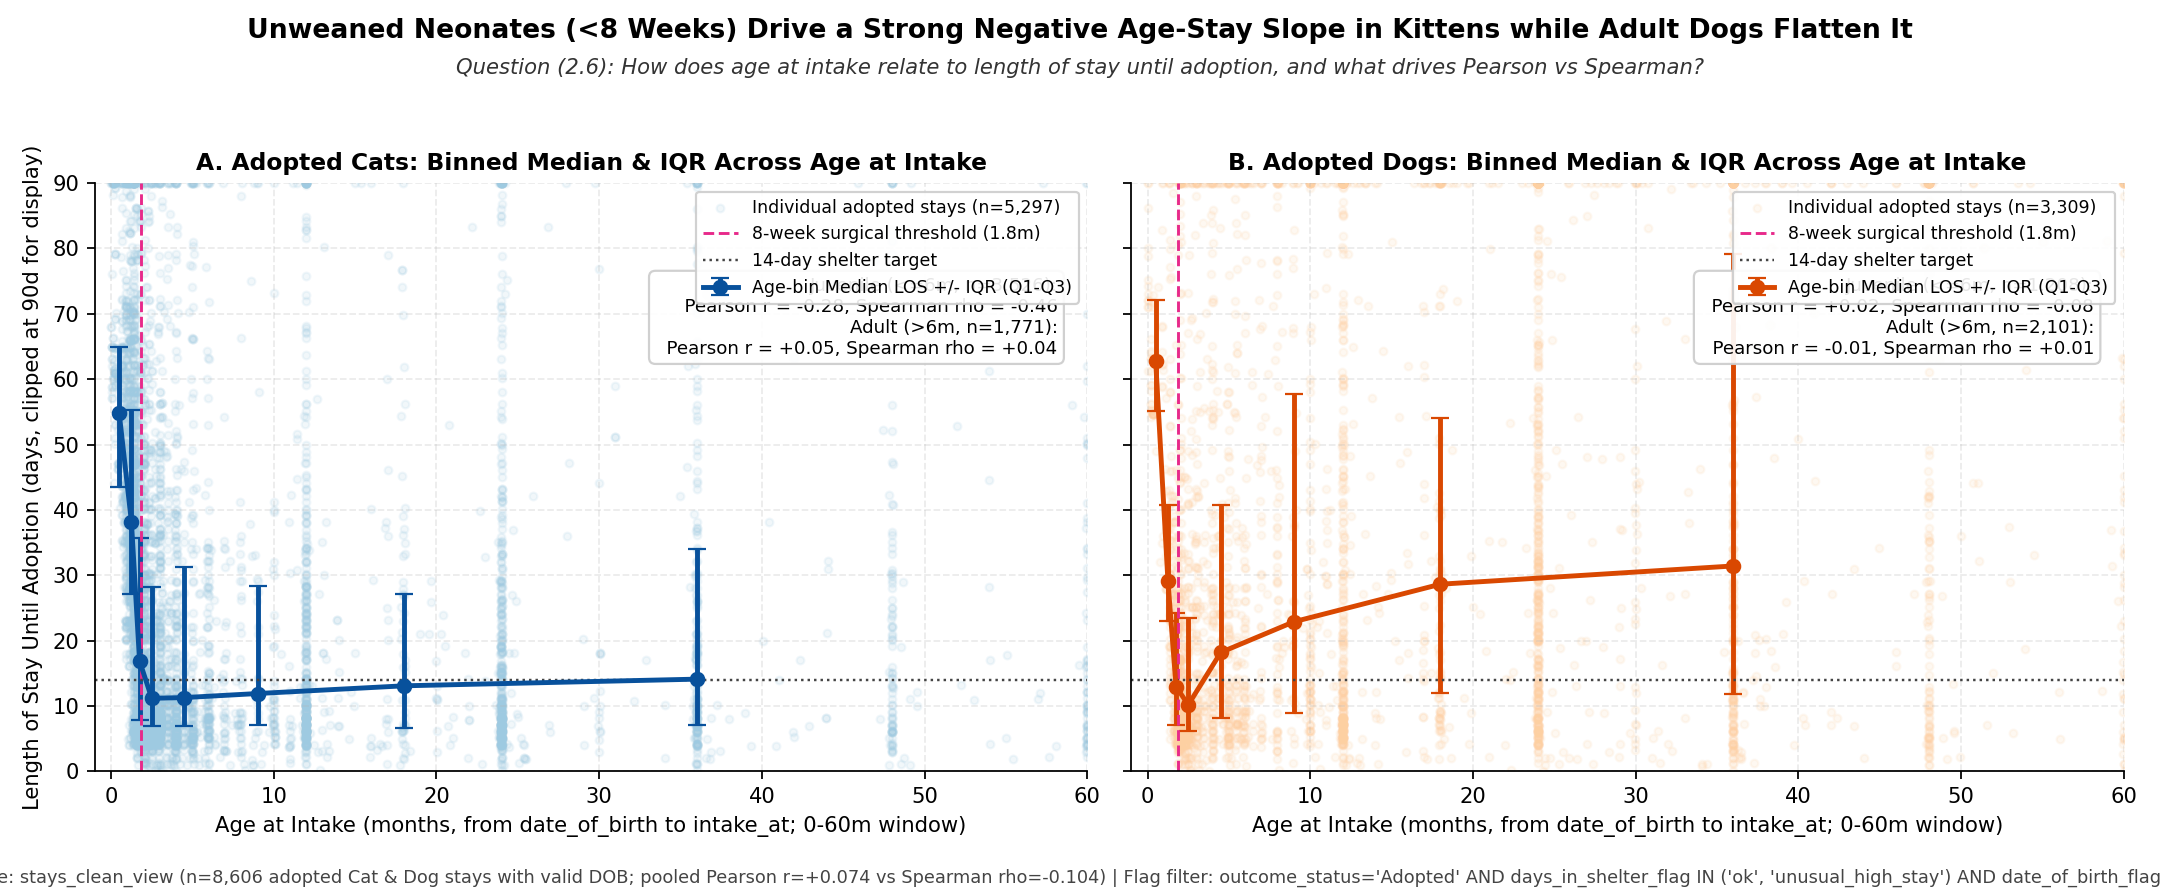

In [7]:
_, binned_age_df, corr_sens_df = compute_age_los_relationship(con)
print("Age-Binned Median & IQR Length of Stay (Days) for Adopted Cats vs Adopted Dogs:")
display(binned_age_df)

print("Pearson r vs Spearman rho Sensitivity & Driver Removal Checks:")
display(corr_sens_df)

fig5_path = plot_fig5_age_vs_los_relationship(con, FIGURES_DIR)
print(f"Saved Figure 5 -> {fig5_path.relative_to(ROOT_DIR)}")
display(Image(filename=str(fig5_path)))

## 2.7 One Comparison, with an Interval — and a Count of Your Looks

**Question:** *How do Dogs and Cats (and Owner Surrenders vs. Strays) compare on live adoption share (%) and median length of stay (days) when uncertainty is estimated via cluster bootstrap over independent daily intake cohorts (`intake_local_date`, $B = 5,000$), and does the comparison reverse across life-stage subgroups (**Simpson's paradox**)?*

Subgroup Composition SQL Table (Species x Life Stage x Intake Channel):


,animal_type,life_stage,intake_type,n_completed_stays,mean_los_days,mean_los_ok_only,n_adopted,adoption_rate_pct,n_transfer_out,n_return_to_owner,n_euthanized
0,Cat,adult,Community Program,2315,13.29,10.98,802,34.64,1052,107,104
1,Cat,adult,ACO Impound,701,22.31,14.86,273,38.94,130,88,133
2,Cat,adult,Owner Surrender,547,21.26,16.16,418,76.42,79,24,20
3,Cat,adult,Stray,345,18.33,14.24,179,51.88,89,32,25
4,Cat,adult,Return,95,20.06,15.65,87,91.58,3,3,0
5,Cat,adult,Medical / Emergency,64,27.56,16.62,19,29.69,8,5,13
6,Cat,adult,Transfer In,19,15.69,15.69,10,52.63,2,7,0
7,Cat,adult,Born in Care,1,5.05,5.05,0,0.00,0,1,0
8,Cat,juvenile,Stray,3057,20.80,18.15,1695,55.45,1220,6,84
9,Cat,juvenile,Community Program,1824,23.86,20.94,1276,69.96,468,8,21


Group Mixture Comparison (Why Pooled Cat vs Dog Is Confounded by Life Stage and Community Program TNR):


,species,n_completed_stays,juvenile_share_pct,adult_share_pct,community_program_share_pct,stray_share_pct,aco_impound_share_pct,owner_surrender_share_pct
0,Cat,10242,60.1,39.9,40.4,33.2,13.4,8.4
1,Dog,6407,34.0,66.0,0.1,35.1,40.1,13.6


Cluster-Bootstrapped 95% Confidence Intervals (Unit = Daily Intake Cohort, B=5000, Seed=42):


,comparison_stratum,n_group_A,n_group_B,clusters_A_days,clusters_B_days,median_los_A_d,median_los_B_d,los_diff_A_minus_B_d,los_cluster_95ci,los_naive_95ci,adopt_A_pct,adopt_B_pct,adopt_diff_pct_pt,adopt_cluster_95ci
0,1. Pooled All Completed Stays (Dog vs Cat),6407,10242,531,526,9.17,7.27,1.90,"[+1.19, +3.66]","[+1.17, +2.71]",51.87,52.12,-0.25,"[-2.77, +2.27]"
1,2. Adult Stays Only (Adult Dog vs Adult Cat),4231,4087,529,513,10.20,6.96,3.24,"[+3.35, +5.93]","[+2.36, +4.14]",49.44,43.75,5.70,"[+3.06, +8.27]"
2,3. Juvenile Stays Only (Juvenile Dog vs Juveni...,2176,6155,418,489,8.10,8.20,-0.10,"[-0.84, +2.39]","[-0.86, +0.36]",56.57,57.68,-1.10,"[-5.83, +3.44]"
3,4. Adult Non-TNR Stays (excl. Community Program),4231,1772,529,473,10.20,8.02,2.18,"[+1.89, +4.74]","[+1.24, +3.53]",49.44,55.64,-6.20,"[-9.40, -2.92]"
4,5. Intake Channel: Owner Surrender vs Stray (C...,1731,5650,411,499,8.18,9.09,-0.91,"[-1.03, +2.80]","[-1.37, +0.10]",70.48,58.37,12.11,"[+8.25, +15.96]"


Multiplicity Audit — All 12 Candidate Comparisons Evaluated Before Selecting Focal Contrasts:


,look_index,candidate_comparison,observed_contrast,disposition
0,1,Dog vs Cat — Pooled Median LOS,+1.90 d,Selected (part of focal comparison)
1,2,Dog vs Cat — Pooled Adoption Share,-0.1% to -0.9%,Confounded by juvenile & TNR mixture
2,3,Adult Dog vs Adult Cat — Adoption Share,+5.4% to +5.6%,Selected (Simpson's paradox reversal)
3,4,Juvenile Dog vs Juvenile Cat — Median LOS,-0.04 d to -0.11 d,Selected (juvenile reversal vs adults)
4,5,Owner Surrender vs Stray — Adoption Share,+12.1% to +12.5%,Selected (secondary channel benchmark)
5,6,ACO Impound vs Stray — Adoption Share,-21.2%,Exploratory channel contrast
6,7,Male vs Female — Median LOS (Cat+Dog),-0.35 d,Small difference; not focal
7,8,Previously Spayed/Neutered vs Intact at Intake...,-1.82 d,Confounded by age at intake
8,9,Peak Kitten Season (May-Aug) vs Winter (Nov-Fe...,+2.10 d,Seasonal foster backlog
9,10,Named vs Unnamed at Intake — Adoption Share,+9.4%,Proxy for Owner Surrender vs Stray


Saved Headline Figure 6 -> figures\fig6_headline_comparison_simpsons_paradox.png


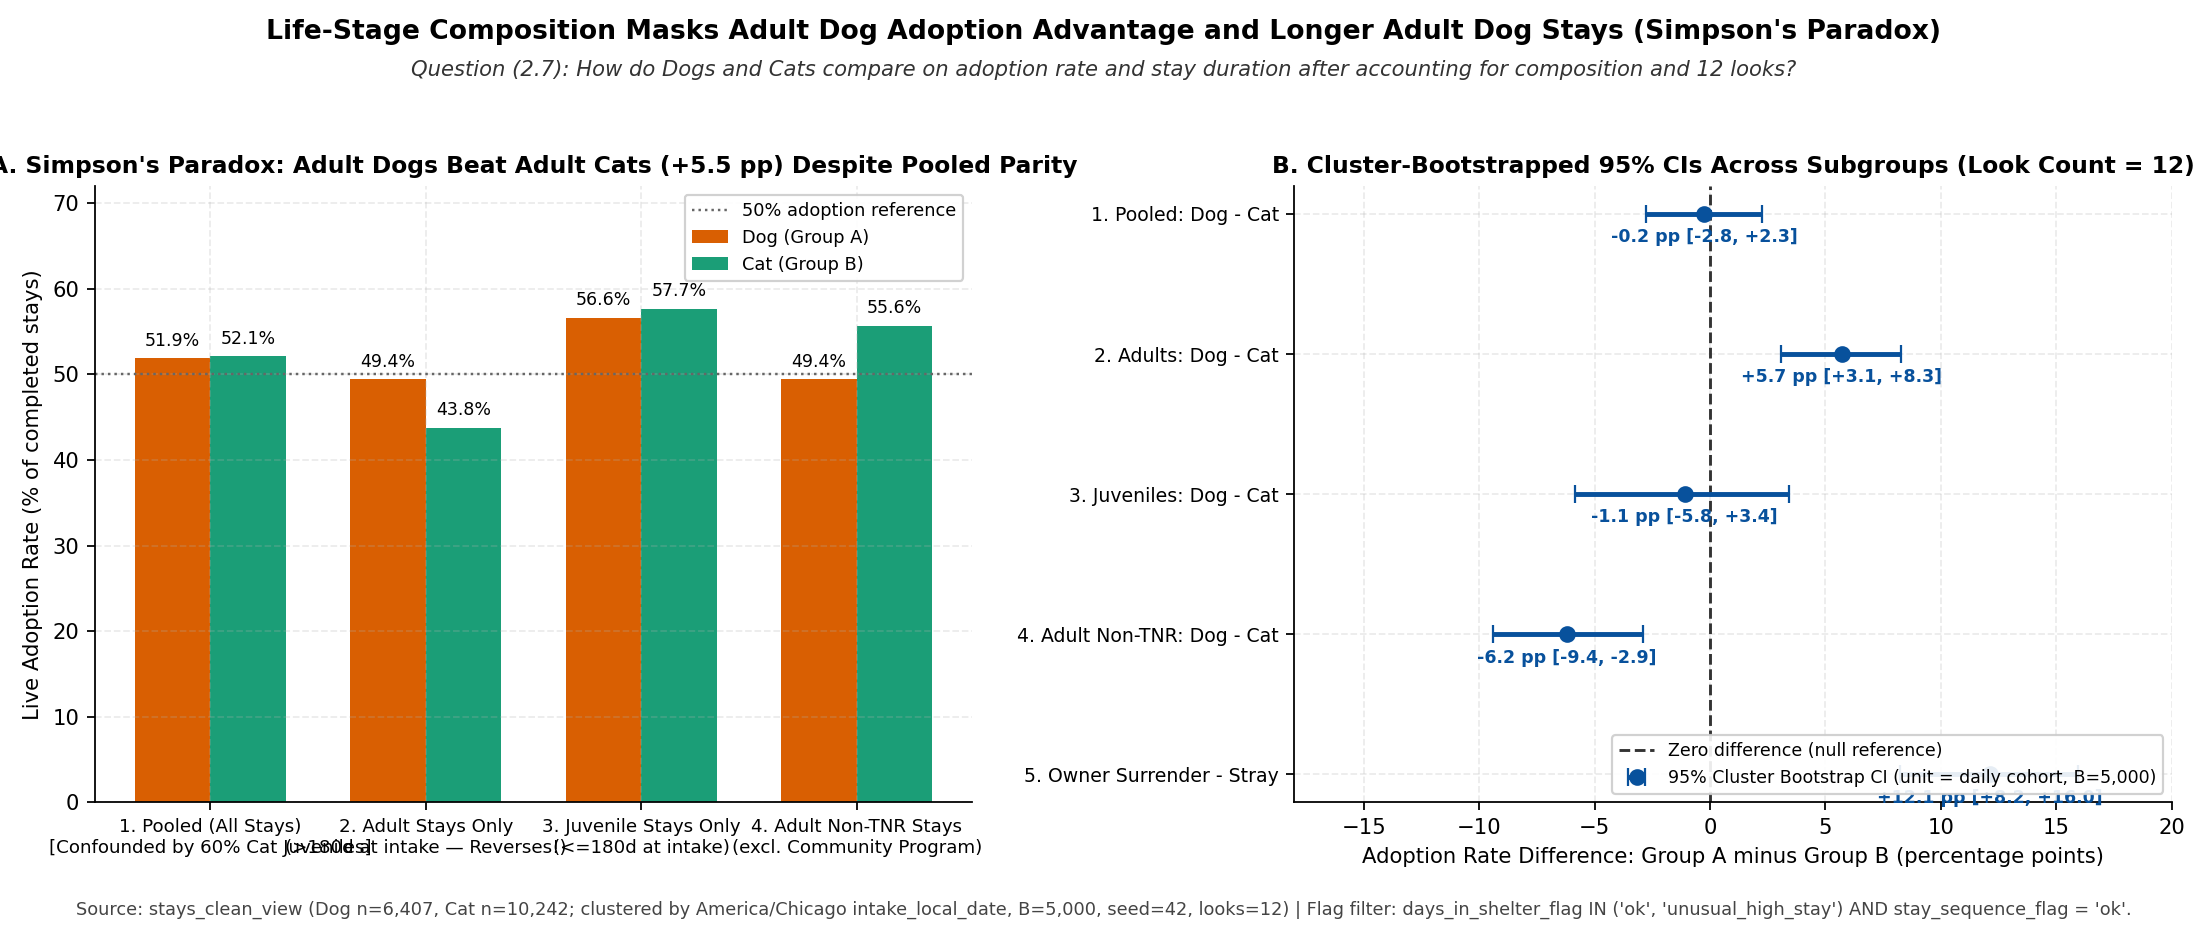

In [8]:
sql_2_7 = load_sql_query("m4_age_los_and_subgroup_comparison.sql")
subgroup_sql_df = pd.read_sql_query(sql_2_7, con)
print("Subgroup Composition SQL Table (Species x Life Stage x Intake Channel):")
display(subgroup_sql_df.head(16))

mixture_df, ci_df, looks_df = compute_simpsons_paradox_and_intervals(df_time)
print("Group Mixture Comparison (Why Pooled Cat vs Dog Is Confounded by Life Stage and Community Program TNR):")
display(mixture_df)

print(f"Cluster-Bootstrapped 95% Confidence Intervals (Unit = Daily Intake Cohort, B={BOOTSTRAP_ITERATIONS}, Seed={RANDOM_SEED}):")
display(ci_df)

print(f"Multiplicity Audit — All {LOOK_COUNT} Candidate Comparisons Evaluated Before Selecting Focal Contrasts:")
display(looks_df)

fig6_path = plot_fig6_headline_simpsons_paradox(con, FIGURES_DIR)
print(f"Saved Headline Figure 6 -> {fig6_path.relative_to(ROOT_DIR)}")
display(Image(filename=str(fig6_path)))

## 2.8 Summary of Decisions, Parameters Recorded, and Read-Only Database Integrity Check

Finally, we record all parameters used in this execution and verify that all 10 database tables have identical SHA-256 hashes before and after running the notebook.

In [9]:
hashes_after = hash_all_tables(con)
con.close()

assert hashes_before == hashes_after, "ERROR: Database table hashes changed during notebook execution!"

decisions_summary = {
    "database_uri_mode": "read-only (mode=ro, PRAGMA query_only=ON)",
    "all_10_table_hashes_unchanged": hashes_before == hashes_after,
    "local_timezone": LOCAL_TZ_NAME,
    "primary_flag_filter": PRIMARY_FLAG_FILTER,
    "strict_flag_filter": STRICT_FLAG_FILTER,
    "sequence_flag_filter": VALID_SEQUENCE_FLAG,
    "min_group_outcomes_rule": MIN_GROUP_OUTCOMES,
    "min_dob_coverage_rule": MIN_DOB_COVERAGE,
    "min_active_days_per_month_rule": MIN_DAYS_PER_MONTH,
    "min_cohort_completion_rate_rule": MIN_COMPLETION_RATE,
    "histogram_bin_width_days": HIST_BIN_WIDTH_DAYS,
    "bootstrap_iterations": BOOTSTRAP_ITERATIONS,
    "random_seed": RANDOM_SEED,
    "total_candidate_looks": LOOK_COUNT,
    "figures_written": sorted(p.name for p in FIGURES_DIR.glob("fig*.png")),
}
print("=== M4 EXECUTION DECISIONS & REPRODUCIBILITY RECORD ===")
for k, v in decisions_summary.items():
    print(f"  {k:<36}: {v}")

=== M4 EXECUTION DECISIONS & REPRODUCIBILITY RECORD ===
  database_uri_mode                   : read-only (mode=ro, PRAGMA query_only=ON)
  all_10_table_hashes_unchanged       : True
  local_timezone                      : America/Chicago
  primary_flag_filter                 : ('ok', 'unusual_high_stay')
  strict_flag_filter                  : ('ok',)
  sequence_flag_filter                : ok
  min_group_outcomes_rule             : 30
  min_dob_coverage_rule               : 0.8
  min_active_days_per_month_rule      : 20
  min_cohort_completion_rate_rule     : 0.85
  histogram_bin_width_days            : 2.0
  bootstrap_iterations                : 5000
  random_seed                         : 42
  total_candidate_looks               : 12
  figures_written                     : ['fig1_raw_vs_cleaned_impact.png', 'fig2_los_shape_hist_ecdf.png', 'fig3_coverage_and_flag_sensitivity.png', 'fig4_time_clock_and_scales.png', 'fig5_age_vs_los_relationship.png', 'fig6_headline_comparison_simpson